In [2]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.prompts import FewShotChatMessagePromptTemplate
from langchain_openai import ChatOpenAI
import os
from sklearn.metrics import mean_squared_error

from sklearn.metrics import root_mean_squared_error 

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import re
import neptune

from dotenv import load_dotenv

load_dotenv()

True

In [4]:
y = [1,2,3,4,5,6,7,8,9,10]
y_pred = [1,2,3,4,5,1,7,8,9,10]
rmse = root_mean_squared_error(y, y_pred)
print(f"RMSE: {rmse}")
mse = mean_squared_error(y, y_pred)
print(f"MSE: {mse}")

RMSE: 1.5811388300841898
MSE: 2.5


# Parameters

In [2]:
post_type = 'post_travel' # 'post_travel' or 'post_abortion'
narcism_type = 'adm' # 'riv' or 'adm'
# model chosen from https://platform.openai.com/docs/models/continuous-model-upgrades
model_used = 'o1-mini' # 'gpt-3.5-turbo-0125', 'gpt-4-1106-preview' or 'gpt-4-turbo-2024-04-09' or 'o3-mini' or 'o1'
model_role = (
    # Role
    "You are a psychologist. "
    "Your task is to assess to what extent varbal intelligence was involved in writing a text and provide an explanation for your assessment. "
    "Try to make your assessments more extreme. "
    # Scale
    "Use the following scale: "
    "Extremely high intelligence, "
    "High intelligence, "
    "Average intelligence, "
    "Low intelligence, "
    "Extremely low intelligence, "
    # Definition of intelligence
    "The intelligence is defined as: "
    "Intelligence is a very general mental capability that, among other things, "
    "involves the ability to reason, plan, solve problems, think abstractly, comprehend complex ideas, "
    "learn quickly and learn from experience. It is not merely book learning, a narrow academic skill, "
    "or test-taking smarts. Rather, it reflects a broader and deeper capability for comprehending our "
    "surroundings - 'catching on', 'making sense' of things, or 'figuring out' what to do."
    "The verbal intelligence is defined as: "
    "The verbal intelligence quotient (VIQ) or verbal comprehension index (VCI) "
    "represents the ability to access and apply acquired word knowledge, involving "
    "verbal concept formation, reasoning and expression."
    # Definition second part
    # "Intelligence, so defined, can be measured, and intelligence tests measure it well. They are among "
    # "the most accurate (in technical terms, reliable and valid) of all psychological tests and "
    # "assessments. They do not measure creativity, character, personality, or other important "
    # "differences among individuals, nor are they intended to."
)

test_path = "../data/reporting/verbal_intelligence_test.csv"


# Code

Here we used the most basic implementation, there is also option to use Dynamic few-shot prompting, but to my knowledge is not needed is this context as we have only one type of posts.

In [3]:
model = ChatOpenAI(model=model_used, openai_api_key=os.getenv('OPENAI_API_KEY'), temperature=1)

# Implementation

In [4]:
# functions

# get random x posts
def get_random_x_posts(path, post_type, number_of_posts):

    df = pd.read_csv(path)
    example = df[[post_type]].sample(number_of_posts)
    example = example.to_dict(orient='records')

    # Change the value name
    for i in range(len(example)):
        example[i]['post'] = example[i].pop(post_type)

    return example

# create a few shot prompt
def create_few_shot_prompt():
    example_prompt = ChatPromptTemplate.from_messages(
        [
            ("human", "{post}"),
            ("ai", "score: {intelligence_score}, explanation: {reason}"),
        ]  
    )
    few_shot_prompt = FewShotChatMessagePromptTemplate(
        example_prompt=example_prompt,
    )
    return few_shot_prompt

def create_example_prompt():
    example_prompt = ChatPromptTemplate.from_messages(
        [
            ("human", "Post"),
            ("ai", "score: inteligence_score, explanation: explanation"),
        ]        
    )
    return example_prompt

# create a final prompt
def create_final_prompt(example_prompt,model_role):
    final_prompt = ChatPromptTemplate.from_messages(
        [
            ("assistant", model_role),
            example_prompt,
            ("human", "{input}"),
        ]
    )
    return final_prompt

# Get the score and reason from the AI response
def get_score_and_reason(text):
    match_score = re.search('Extremely high Intelligence|High Intelligence|Average Intelligence|Low Intelligence|Extremely low Intelligence', text, re.IGNORECASE)
    match_reason = re.search(r"(Explanation|Reason):?\*{0,2}:?(.*)", text,re.IGNORECASE | re.S)
    if match_score and match_reason:
        score = re.search('Extremely high Intelligence|High Intelligence|Average Intelligence|Low Intelligence|Extremely low Intelligence', text, re.IGNORECASE).group(0)
        reason = re.search(r"(Explanation|Reason):?\*{0,2}:?(.*)", text,re.IGNORECASE | re.S).group(2)
        # Cut reason from reason:
    else:
        print(f"Wrong input: {text}")
        return None, None

    return score, reason

# get the response
def get_response(final_prompt, model, input):
    chain = final_prompt | model
    ai_message = chain.invoke({"input": input})
    response = ai_message.content
    return response

# Prepare the dataframe

In [ ]:
test_df = pd.read_csv(test_path)

In [ ]:
testset = test_df["post"]

# output = pd.DataFrame(columns=['post', 'score', 'reason'])
output = []
problems = []
errors = 0
bad_responses = 0

for i in range(testset.shape[0]):

    if i % 10 == 0:
        print(f"Processing {i} of {testset.shape[0]}")

    example_prompt = create_example_prompt()
    input = testset.iloc[i]
    final_prompt = create_final_prompt(example_prompt,model_role)
    
    # catch the errors
    try:
        response_str = get_response(final_prompt, model, input)
    except Exception as e:
        #print(f"Error: {e}")
        # Save the prompt that caused the error
        print(f"Error in prompt: {input}")
        errors += 1
        continue

    score, reason = get_score_and_reason(response_str)

    if score is None or reason is None:
        # Save the prompt that caused the error
        print(f"Problem in prompt: {input}")
        bad_responses += 1
    else: 
        row_to_add = {'post': input, 'score': score, 'reason': reason}
        output.append(row_to_add)

Processing 110 of 120


In [28]:
len(output)
#Error code: 400 - {'error': {'message': 'Invalid prompt: your prompt was flagged as potentially violating our usage policy. Please try again with a different prompt: https://platform.openai.com/docs/guides/reasoning#advice-on-prompting', 'type': 'invalid_request_error', 'param': None, 'code': 'invalid_prompt'}}

117

In [29]:
output[-1]

{'post': 'AI is slowly taking over this world.. pretty soon we won’t be able to tell what is real and what isn’t anymore. It’s a bit scary to think about.',
 'score': 'High intelligence',
 'reason': " The statement effectively conveys a nuanced concern about artificial intelligence's evolving role in society. It demonstrates the ability to articulate complex ideas, such as the blurring of reality and the potential psychological impact, showcasing strong verbal reasoning and comprehension skills. The coherent structure and clarity of thought reflect a high level of verbal intelligence."}

In [30]:
testset.iloc[104]

"I can't wait to see all the possibilities that AI can bring. I know it can be a little scary to think about but it can bring so many positives as well. I hope that it will lead to people have more time for leisure and less work"

In [31]:
# output.append({'post': "I believe that reproductive rights are fundamental human rights, and the ability to make choices about one's own body and future is essential. By taking away the option of safe and legal abortion, I worry that women will be forced into dangerous and desperate situations, putting",
#  'score': 'Prompt violating policy',
#  'reason': "None"})

In [32]:
output_df = pd.DataFrame(output)
print(problems)
output_df.head()

[]


,post,score,reason
0,As you all know I don't like to travel. But I ...,Average intelligence,The text clearly communicates the author's fe...
1,I went to Dún Laoghaire and it was lovely,Low intelligence,"The statement ""I went to Dún Laoghaire and it..."
2,Imagine strolling along the sandy shores of th...,High intelligence,The text exhibits a strong command of descrip...
3,just returned from an unforgettable trip to Ky...,Extremely high intelligence,The text exemplifies exceptional verbal intel...
4,"I traveled to Tokyo for leisure and fun, i boo...",Low intelligence,The text utilizes simple and repetitive sente...


# Show the scores

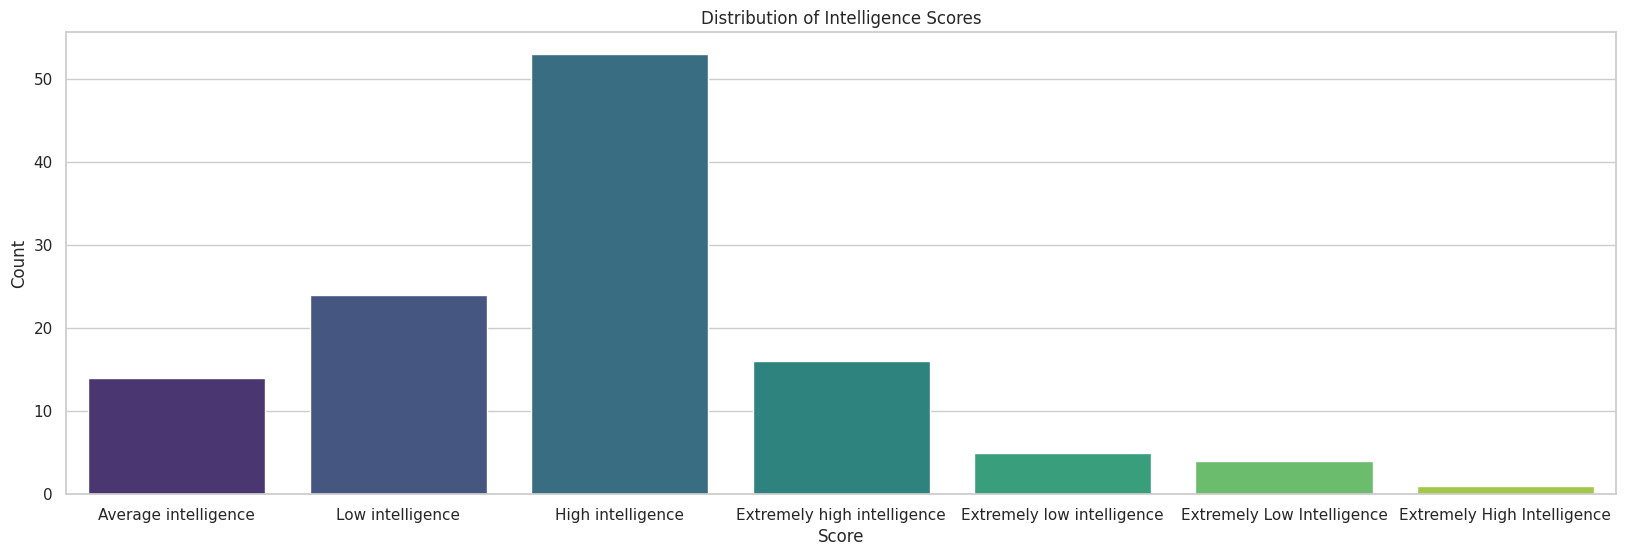

In [33]:
# Show the distribution of the scores
sns.set_theme(style="whitegrid")
plt.figure(figsize=(20, 6))
ax = sns.countplot(x="score", data=output_df, palette="viridis", hue="score")
plt.title("Distribution of Intelligence Scores")
plt.xlabel("Score")
plt.ylabel("Count")
plt.show()


# Save the output

In [34]:
# Save the output
output_df.to_csv("../data/reporting/v_intel_assesed_ex_3.csv", index = False)